# Import

In [70]:
import pandas as pd
import networkx as nx

nodes = pd.read_csv("data/nodes.csv", dtype={"id": str})
edges = pd.read_csv("data/edges.csv", dtype={"id": str, "source": str, "target": str})

pos = {int(i): (x, y) for i, x, y in zip(nodes["id"], nodes["x"], nodes["y"])}

V = 20
edges["weight"] = edges["length"] / V
edges = edges.sort_values("weight", ascending=False)

REMOVE_CLOSED= False
E = edges[edges.closed == 0] if REMOVE_CLOSED else edges

G = nx.from_pandas_edgelist(E, "source", "target",
                            edge_attr=["id", "type", "weight", "closed"])


nx.set_node_attributes(G, pd.Series(nodes.type.values, index=nodes.id).to_dict(), "type")
G = nx.relabel_nodes(G, int)


# Plotting

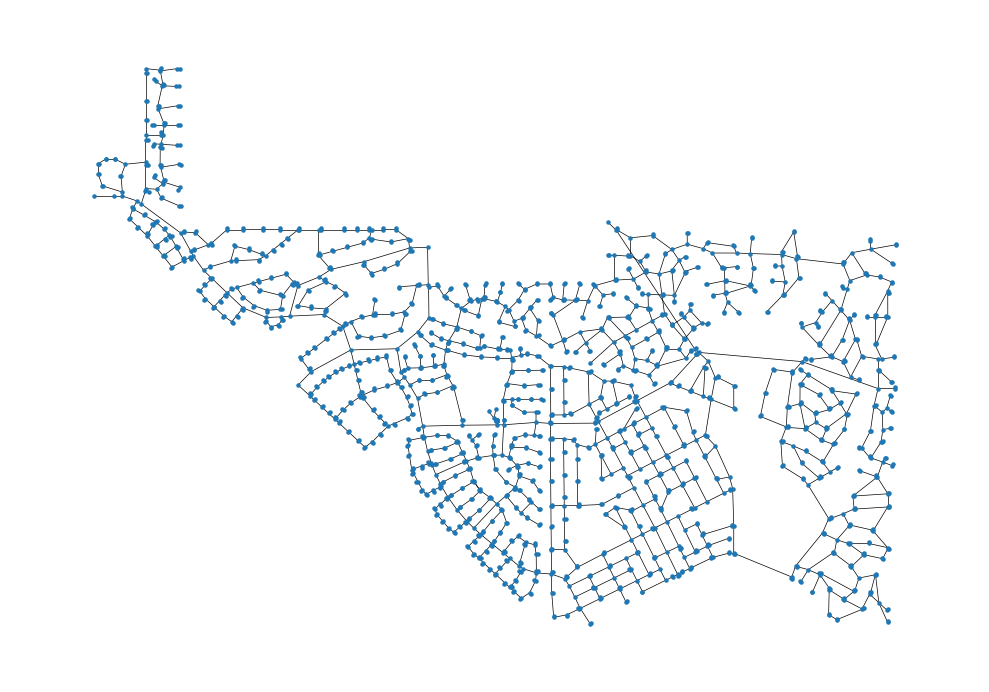

In [71]:
fig, ax = plt.subplots(figsize=(10, 10))
nx.draw(G, pos=pos, node_size=5, width=0.5)
ax.set_aspect("equal") 
plt.tight_layout()
plt.show()

# Task 1

In [72]:
for i in G.nodes():
    if G.nodes[i]["type"] == "Junction":
        G.nodes[i]["leaf"] = G.degree[i] == 1


In [73]:
count=0
degli=0

for i in G.nodes():
    if G.nodes[i]["type"] == "Junction" and G.nodes[i]["leaf"] == False:
        count+=1
        degli+=G.degree[i]

degli/count


2.9837545126353793

In [74]:
reservoir_dijkstra = {}
for i in G.nodes():
    if G.nodes[i]["type"] == "Reservoir":
        reservoir_dijkstra[i] = nx.single_source_dijkstra(G, i, weight="weight")

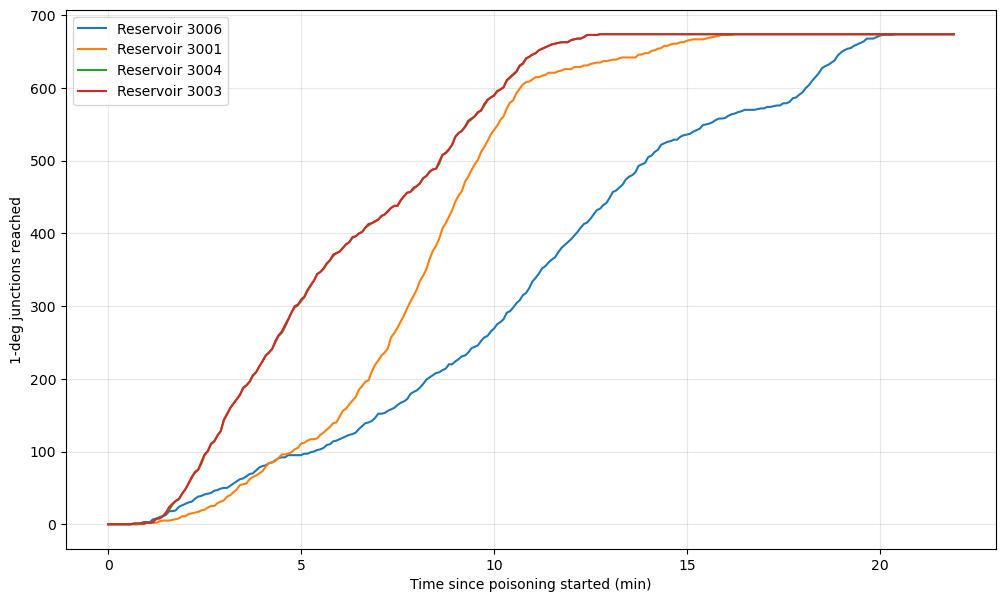

In [75]:
import numpy as np
import matplotlib.pyplot as plt

leaves = [n for n in G.nodes() if G.nodes[n].get("leaf")]
grid = np.arange(0, 22 * 60, 5)

fig, ax = plt.subplots(figsize=(12, 7))
for r, (dist, _) in reservoir_dijkstra.items():
    times = np.array([dist[n] for n in leaves])
    counts = []
    for t in grid:
        counts.append((times <= t).sum())
    ax.plot(grid / 60, counts, label=f"Reservoir {r}")

ax.set_xlabel("Time since poisoning started (min)")
ax.set_ylabel("1-deg junctions reached")
ax.legend()
ax.grid(alpha=0.3)
plt.show()